In [4]:
!pip install statsmodels

from statsmodels.nonparametric.smoothers_lowess import lowess
import numpy as np
import matplotlib.pyplot as plt

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 980.9 kB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 5.4 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 233.3/233.3 kB 5.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 7.6 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 474.0/474.0 kB 4.8 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 236.3/236.3 kB 9.2 MB/s eta 0:00:00


# Part 2

We use the STAR mode

$$
X_{t+1} = \begin{cases}
4 + 0.5X_t + \varepsilon_{t+1}, & X_t < 0, \\[4pt]
-4 - 0.5X_t + \varepsilon_{t+1}, & X_t \geq 0.
\end{cases}
$$

$$
M(x) =
\begin{cases}
4 + 0.5x, & x < 0, \\[4pt]
-4 - 0.5x, & x \geq 0.
\end{cases}
$$

In [5]:


# Range of x values
x = [-5, 2, 0, 2, 5]

a = [[4, 0.5],  # Regime 1
     [-4, -0.5]]  # Regime 2

# Theoretical conditional mean
def conditional_mean(x, a):
    if x < 0:
        return a[0][0] + a[0][1] * x
    else:
        return a[1][0] + a[1][1] * x

print("Theoretical conditional means:")
for val in x:
    print(f"x = {val}: E[X_t | X_{{t-1}} = {val}] = {conditional_mean(val, a)}")

Theoretical conditional means:
x = -5: E[X_t | X_{t-1} = -5] = 1.5
x = 2: E[X_t | X_{t-1} = 2] = -5.0
x = 0: E[X_t | X_{t-1} = 0] = -4.0
x = 2: E[X_t | X_{t-1} = 2] = -5.0
x = 5: E[X_t | X_{t-1} = 5] = -6.5


In [8]:
# ----------------------------------------
# SETAR model
# ----------------------------------------
def SETAR(X, threshold, a, eps):

    for t in range(1, len(X)):

        if X[t - 1] < threshold:
            X[t] = (
                a[0][0]
                + a[0][1] * X[t - 1]
                + eps[t]
            )

        else:
            X[t] = (
                a[1][0]
                + a[1][1] * X[t - 1]
                + eps[t]
            )

    return X


# ----------------------------------------
# Parameters
# ----------------------------------------
n = 1000

a = [
    [4, 0.5],       # Regime 1
    [-4, -0.5]      # Regime 2
]

rng = np.random.default_rng(42)

eps = rng.normal(0, 1, n)

X = np.zeros(n)
X[0] = eps[0]


# ----------------------------------------
# Simulate SETAR
# ----------------------------------------
X = SETAR(
    X=X,
    threshold=0,
    a=a,
    eps=eps
)


# ----------------------------------------
# Construct (X_t, X_{t+1}) pairs
# ----------------------------------------
x_data = X[:-1]
y_data = X[1:]


# ----------------------------------------
# Theoretical conditional mean
# ----------------------------------------
def conditional_mean(x, a):

    return np.where(
        x < 0,
        a[0][0] + a[0][1] * x,
        a[1][0] + a[1][1] * x
    )


x_grid = np.linspace(
    x_data.min(),
    x_data.max(),
    500
)

M_true = conditional_mean(x_grid, a)



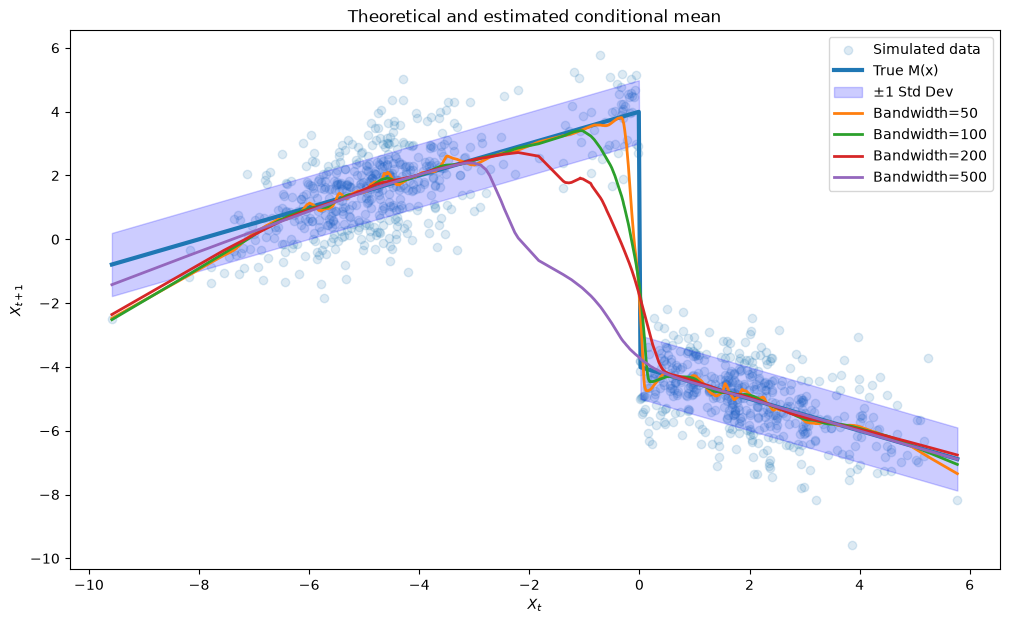

In [20]:
# Bandwidths indicate the number of neighboring points used to estimate the conditional mean at each point. A smaller bandwidth results in a more flexible fit, while a larger bandwidth results in a smoother fit.
bandwidths = [0.05, 0.1, 0.2, 0.5]


residuals = y_data - conditional_mean(x_data, a)
residual_variance = np.var(residuals)
std_dev = np.sqrt(residual_variance)

plt.figure(figsize=(12, 7))

# Simulated observations
plt.scatter(
    x_data,
    y_data,
    alpha=0.15,
    label="Simulated data"
)

# True conditional mean
plt.plot(
    x_grid,
    M_true,
    linewidth=3,
    label="True M(x)"
)

# Confidence band (±1 std dev)
plt.fill_between(
    x_grid,
    M_true - std_dev,
    M_true + std_dev,
    alpha=0.2,
    color='blue',
    label="±1 Std Dev"
)

# Local regression estimates
for bandwidth in bandwidths:
    fitted = lowess(
        endog=y_data,
        exog=x_data,
        frac=bandwidth,
        return_sorted=False
    )

    sort_idx = np.argsort(x_data)
    plt.plot(
        x_data[sort_idx],
        fitted[sort_idx],
        linewidth=2,
        label=f"Bandwidth={bandwidth * n:.0f}"
    )

plt.xlabel(r"$X_t$")
plt.ylabel(r"$X_{t+1}$")
plt.title("Theoretical and estimated conditional mean")
plt.legend()

plt.show()